In [1]:
from pathlib import Path
import sys
import platform
import importlib
import json
import math
import hashlib
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path(r"C:\Users\samya\PyCharmProject\industrial-vision-inspection")

if not PROJECT_ROOT.is_dir():
    raise FileNotFoundError(f"Project directory not found: {PROJECT_ROOT}")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import config
'''
CONFIG_FILE = Path(config.__file__).resolve()
print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Project root:", PROJECT_ROOT)
print("Imported config:", CONFIG_FILE)

if CONFIG_FILE.parent != PROJECT_ROOT.resolve():
    raise RuntimeError(
        f"Unexpected config.py imported from {CONFIG_FILE}; "
        "check for another module named config."
    )
'''
required_config = [
    "PROJECT_DIR", "DATA_DIR", "IMAGE_METADATA_FILE",
    "OBJECT_ANNOTATIONS_FILE", "IMAGE_EXTRACTION_ERRORS_FILE",
    "ANNOTATION_EXTRACTION_ERRORS_FILE", "validate_config"
]
missing_config = [name for name in required_config if not hasattr(config, name)]
if missing_config:
    raise AttributeError(f"Missing required config variables: {missing_config}")

def resolve_config_path(value):
    path = Path(value)
    if path.is_absolute():
        return path.resolve()
    # Relative DATA_DIR and output paths are interpreted relative to project root.
    return (PROJECT_ROOT / path).resolve()

input_paths = {
    "images": resolve_config_path(config.IMAGE_METADATA_FILE),
    "annotations": resolve_config_path(config.OBJECT_ANNOTATIONS_FILE),
    "image_errors": resolve_config_path(config.IMAGE_EXTRACTION_ERRORS_FILE),
    "annotation_errors": resolve_config_path(config.ANNOTATION_EXTRACTION_ERRORS_FILE),
}

EDA_DIR = PROJECT_ROOT / "reports" / "eda"
TABLES_DIR = EDA_DIR / "tables"
PLOTS_DIR = EDA_DIR / "plots"
SAMPLES_DIR = EDA_DIR / "samples"
for folder in (TABLES_DIR, PLOTS_DIR, SAMPLES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

file_status = pd.DataFrame([
    {
        "dataset": name,
        "path": str(path),
        "exists": path.is_file(),
        "size_mb": round(path.stat().st_size / (1024**2), 3) if path.is_file() else np.nan,
    }
    for name, path in input_paths.items()
])
display(file_status)

missing_files = [name for name, path in input_paths.items() if not path.is_file()]
if missing_files:
    raise FileNotFoundError(
        f"Required CSV file(s) missing: {missing_files}. "
        "Check config.py and run data_injection.py if appropriate."
    )

file_status.to_csv(TABLES_DIR / "input_file_status.csv", index=False)
print(f"EDA outputs: {EDA_DIR}")


,dataset,path,exists,size_mb
0,images,C:\Users\samya\PyCharmProject\industrial-visio...,True,0.309
1,annotations,C:\Users\samya\PyCharmProject\industrial-visio...,True,4.705
2,image_errors,C:\Users\samya\PyCharmProject\industrial-visio...,True,0.000
3,annotation_errors,C:\Users\samya\PyCharmProject\industrial-visio...,True,0.000


EDA outputs: C:\Users\samya\PyCharmProject\industrial-vision-inspection\reports\eda


In [7]:
images = pd.read_csv(input_paths["images"])
annotations = pd.read_csv(input_paths["annotations"])
image_errors = pd.read_csv(input_paths["image_errors"])
annotation_errors = pd.read_csv(input_paths["annotation_errors"])

datasets = {
    "images": images,
    "annotations": annotations,
    "image_errors": image_errors,
    "annotation_errors": annotation_errors,
}

overview = pd.DataFrame([
    {
        "dataset": name,
        "rows": len(df),
        "columns": df.shape[1],
        "memory_mb": round(df.memory_usage(index=True, deep=True).sum() / (1024**2), 3),
    }
    for name, df in datasets.items()
])
display(overview)

,dataset,rows,columns,memory_mb
0,images,821,16,0.721
1,annotations,10226,24,7.414
2,image_errors,0,5,0.000
3,annotation_errors,0,5,0.000


In [8]:
for name, df in datasets.items():
    print(f"\n{'='*70}\n{name.upper()}\n{'='*70}")
    print("Columns:", df.columns.tolist())
    display(df.dtypes.astype(str).rename("dtype").to_frame())
    display(df.head(5))
    print("Missing values by column:")
    display(df.isna().sum().rename("missing_count").to_frame())



IMAGES
Columns: ['image_id', 'image_name', 'image_path', 'json_path', 'image_width_px', 'image_height_px', 'image_format', 'image_mode', 'channel_count', 'file_size_bytes', 'sha256', 'labelme_version', 'json_image_width', 'json_image_height', 'annotation_count', 'created_at']


,dtype
image_id,str
image_name,str
image_path,str
json_path,str
image_width_px,int64
image_height_px,int64
image_format,str
image_mode,str
channel_count,int64
file_size_bytes,int64


,image_id,image_name,image_path,json_path,image_width_px,image_height_px,image_format,image_mode,channel_count,file_size_bytes,sha256,labelme_version,json_image_width,json_image_height,annotation_count,created_at
0,73d866ee0dffd1b2,00001.png,C:\Users\samya\PyCharmProject\dataset-ind-visi...,C:\Users\samya\PyCharmProject\dataset-ind-visi...,1920,1080,PNG,RGB,3,1970722,73d866ee0dffd1b27b44daac1e1c4534196ecd62a7c5bd...,5.6.1,1920,1080,19,2026-10-18T07:04:22.117910+00:00
1,290ddaf57099e6e6,00002.png,C:\Users\samya\PyCharmProject\dataset-ind-visi...,C:\Users\samya\PyCharmProject\dataset-ind-visi...,1920,1080,PNG,RGB,3,1950578,290ddaf57099e6e6c8488eb3eafda4c61e52b4d5a7c773...,5.6.1,1920,1080,19,2026-10-18T07:04:22.289486+00:00
2,ae9cc3623cdb3372,00003.png,C:\Users\samya\PyCharmProject\dataset-ind-visi...,C:\Users\samya\PyCharmProject\dataset-ind-visi...,1920,1080,PNG,RGB,3,1961830,ae9cc3623cdb3372c2fc6a5ca5b9c25b8d8ac950a0cb1c...,5.6.1,1920,1080,22,2026-10-18T07:04:22.467537+00:00
3,5859a9ea09311ec1,00004.png,C:\Users\samya\PyCharmProject\dataset-ind-visi...,C:\Users\samya\PyCharmProject\dataset-ind-visi...,1920,1080,PNG,RGB,3,2138005,5859a9ea09311ec1e4b703683228a165549eb3ac4d6beb...,5.6.1,1920,1080,20,2026-10-18T07:04:22.659544+00:00
4,d0a480e723109c2c,00005.png,C:\Users\samya\PyCharmProject\dataset-ind-visi...,C:\Users\samya\PyCharmProject\dataset-ind-visi...,1920,1080,PNG,RGB,3,2026403,d0a480e723109c2c92167a26f69a08edd58dc6d152ff61...,5.6.1,1920,1080,19,2026-10-18T07:04:22.871296+00:00


Missing values by column:


,missing_count
image_id,0
image_name,0
image_path,0
json_path,0
image_width_px,0
image_height_px,0
image_format,0
image_mode,0
channel_count,0
file_size_bytes,0


...


ANNOTATION_ERRORS
Columns: ['file_name', 'file_path', 'error_type', 'error_message', 'created_at']


,dtype
file_name,object
file_path,object
error_type,object
error_message,object
created_at,object


,file_name,file_path,error_type,error_message,created_at


Missing values by column:


,missing_count
file_name,0
file_path,0
error_type,0
error_message,0
created_at,0


In [9]:
def duplicate_count(series):
    return int(series.duplicated(keep=False).sum()) if series is not None else 0

image_ids = images["image_id"] if "image_id" in images else pd.Series(dtype="object")
annotation_ids = annotations["annotation_id"] if "annotation_id" in annotations else pd.Series(dtype="object")
annotation_image_ids = set(annotations["image_id"].dropna().astype(str)) if "image_id" in annotations else set()
image_id_set = set(images["image_id"].dropna().astype(str)) if "image_id" in images else set()

summary_metrics = [
    ("image_rows", len(images)),
    ("unique_nonmissing_image_ids", images["image_id"].nunique(dropna=True) if "image_id" in images else np.nan),
    ("image_rows_with_duplicate_id", duplicate_count(image_ids)),
    ("annotation_rows", len(annotations)),
    ("unique_nonmissing_annotation_ids", annotations["annotation_id"].nunique(dropna=True) if "annotation_id" in annotations else np.nan),
    ("annotation_rows_with_duplicate_id", duplicate_count(annotation_ids)),
    ("unique_images_with_annotations", len(annotation_image_ids)),
    ("image_ids_without_matching_annotation", len(image_id_set - annotation_image_ids)),
    ("annotation_image_ids_not_in_image_metadata", len(annotation_image_ids - image_id_set)),
    ("image_extraction_error_rows", len(image_errors)),
    ("annotation_extraction_error_rows", len(annotation_errors)),
]
dataset_summary = pd.DataFrame(summary_metrics, columns=["metric", "value"])
display(dataset_summary)
dataset_summary.to_csv(TABLES_DIR / "dataset_summary.csv", index=False)

# Preserve explicit records for manual investigation.
if "image_id" in images:
    images[images["image_id"].duplicated(keep=False)].to_csv(
        TABLES_DIR / "duplicate_image_ids.csv", index=False
    )
if "annotation_id" in annotations:
    annotations[annotations["annotation_id"].duplicated(keep=False)].to_csv(
        TABLES_DIR / "duplicate_annotation_ids.csv", index=False
    )
if "image_id" in annotations:
    annotations[~annotations["image_id"].astype(str).isin(image_id_set)].to_csv(
        TABLES_DIR / "annotations_with_unknown_image_id.csv", index=False
    )


,metric,value
0,image_rows,821
1,unique_nonmissing_image_ids,821
2,image_rows_with_duplicate_id,0
3,annotation_rows,10226
4,unique_nonmissing_annotation_ids,10226
5,annotation_rows_with_duplicate_id,0
6,unique_images_with_annotations,821
7,image_ids_without_matching_annotation,0
8,annotation_image_ids_not_in_image_metadata,0
9,image_extraction_error_rows,0


In [10]:
# Required fields emitted by the current extraction script.
required_image_columns = [
    "image_id", "image_filename", "image_width_px", "image_height_px",
    "total_pixels", "file_size_bytes", "image_checksum_sha256",
    "total_annotations"
]
required_annotation_columns = [
    "annotation_id", "image_id", "shape_index", "label", "shape_type",
    "x1_px", "y1_px", "x2_px", "y2_px", "bbox_width_px",
    "bbox_height_px", "bbox_area_px2", "bbox_aspect_ratio",
    "bbox_x_center_norm", "bbox_y_center_norm", "bbox_width_norm",
    "bbox_height_norm", "bbox_area_norm", "is_out_of_bounds",
    "points_json", "annotation_flags"
]

schema_issues = []
for dataset_name, df, required in [
    ("images", images, required_image_columns),
    ("annotations", annotations, required_annotation_columns),
]:
    for column in required:
        if column not in df.columns:
            schema_issues.append({
                "dataset": dataset_name,
                "issue": "missing_required_column",
                "column": column,
                "count": 1,
            })

schema_issues_df = pd.DataFrame(
    schema_issues, columns=["dataset", "issue", "column", "count"]
)
display(schema_issues_df)
schema_issues_df.to_csv(TABLES_DIR / "schema_issues.csv", index=False)

missing_summary = []
for name, df in datasets.items():
    for col in df.columns:
        missing_summary.append({
            "dataset": name,
            "column": col,
            "missing_count": int(df[col].isna().sum()),
            "missing_pct": round(float(df[col].isna().mean() * 100), 3) if len(df) else 0.0,
        })
missing_summary_df = pd.DataFrame(missing_summary)
display(missing_summary_df.sort_values(["dataset", "missing_count"], ascending=[True, False]))
missing_summary_df.to_csv(TABLES_DIR / "missing_values_by_column.csv", index=False)

duplicate_rows = []
for name, df in datasets.items():
    duplicate_rows.append({
        "dataset": name,
        "exact_duplicate_rows": int(df.duplicated().sum()),
    })
duplicate_rows_df = pd.DataFrame(duplicate_rows)
display(duplicate_rows_df)
duplicate_rows_df.to_csv(TABLES_DIR / "exact_duplicate_rows.csv", index=False)

# Parse numeric annotation features with coercion on a separate analysis copy.
numeric_annotation_cols = [
    "x1_px", "y1_px", "x2_px", "y2_px", "bbox_width_px",
    "bbox_height_px", "bbox_area_px2", "center_x_px", "center_y_px",
    "bbox_x_center_norm", "bbox_y_center_norm", "bbox_width_norm",
    "bbox_height_norm", "bbox_area_norm", "bbox_aspect_ratio"
]
present_numeric_cols = [c for c in numeric_annotation_cols if c in annotations.columns]
ann_num = annotations.copy()
for col in present_numeric_cols:
    ann_num[col] = pd.to_numeric(ann_num[col], errors="coerce")

numeric_quality = []
for col in present_numeric_cols:
    values = ann_num[col]
    arr = values.to_numpy(dtype=float, na_value=np.nan)
    numeric_quality.append({
        "column": col,
        "missing_or_non_numeric": int(np.isnan(arr).sum()),
        "positive_infinity": int(np.isposinf(arr).sum()),
        "negative_infinity": int(np.isneginf(arr).sum()),
        "unique_nonmissing_values": int(values.nunique(dropna=True)),
    })
numeric_quality_df = pd.DataFrame(numeric_quality)
display(numeric_quality_df)
numeric_quality_df.to_csv(TABLES_DIR / "numeric_quality.csv", index=False)

if "label" in annotations.columns:
    label_values = annotations["label"].dropna().astype(str).str.strip()
    print("Distinct non-empty labels:", sorted(label_values.unique().tolist()))
    print("Blank/whitespace labels:", int(
        annotations["label"].isna().sum()
        + annotations["label"].dropna().astype(str).str.strip().eq("").sum()
    ))

if "shape_type" in annotations.columns:
    print("Shape types:")
    display(annotations["shape_type"].value_counts(dropna=False).rename_axis("shape_type").to_frame("count"))

if "is_out_of_bounds" in annotations.columns:
    print("Existing out-of-bounds flag values:")
    display(annotations["is_out_of_bounds"].value_counts(dropna=False).rename_axis("value").to_frame("count"))


,dataset,issue,column,count
0,images,missing_required_column,image_filename,1
1,images,missing_required_column,total_pixels,1
2,images,missing_required_column,image_checksum_sha256,1
3,images,missing_required_column,total_annotations,1
4,annotations,missing_required_column,shape_index,1
5,annotations,missing_required_column,is_out_of_bounds,1


,dataset,column,missing_count,missing_pct
45,annotation_errors,file_name,0,0.0
46,annotation_errors,file_path,0,0.0
47,annotation_errors,error_type,0,0.0
48,annotation_errors,error_message,0,0.0
49,annotation_errors,created_at,0,0.0
16,annotations,image_id,0,0.0
17,annotations,annotation_id,0,0.0
18,annotations,label,0,0.0
19,annotations,shape_type,0,0.0
20,annotations,points_json,0,0.0


,dataset,exact_duplicate_rows
0,images,0
1,annotations,0
2,image_errors,0
3,annotation_errors,0


,column,missing_or_non_numeric,positive_infinity,negative_infinity,unique_nonmissing_values
0,x1_px,0,0,0,9418
1,y1_px,0,0,0,9237
2,x2_px,0,0,0,9399
3,y2_px,0,0,0,9236
4,bbox_width_px,0,0,0,4172
5,bbox_height_px,0,0,0,4370
6,bbox_area_px2,0,0,0,9083
7,bbox_x_center_norm,0,0,0,9790
8,bbox_y_center_norm,0,0,0,9701
9,bbox_width_norm,0,0,0,3902


Distinct non-empty labels: ['hole', 'screw']
Blank/whitespace labels: 0
Shape types:


,count
shape_type,
rectangle,10226


,label,annotation_count,annotation_pct,images_with_label
0,screw,7941,77.655,796
1,hole,2285,22.345,489


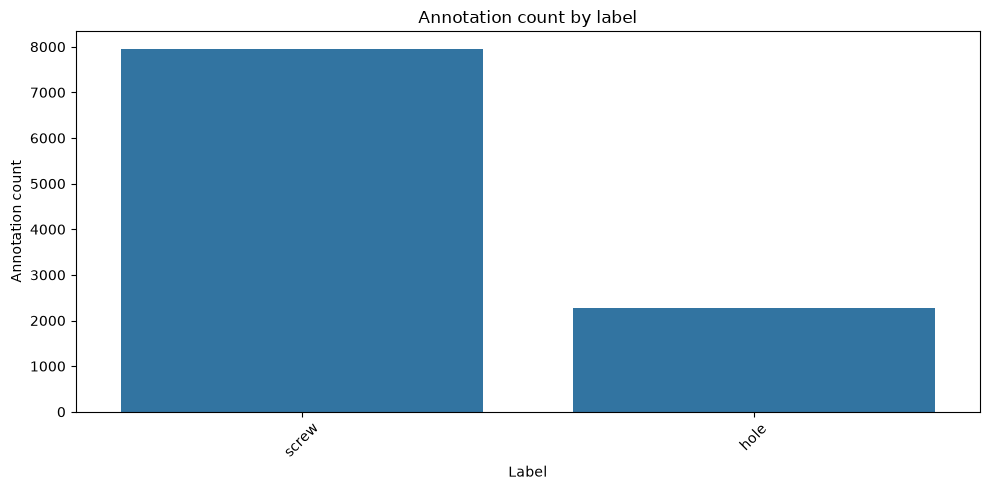

In [11]:
if "label" not in annotations.columns:
    raise KeyError("The annotation CSV has no 'label' column.")

label_series = annotations["label"].fillna("<MISSING>").astype(str).str.strip()
label_counts = label_series.value_counts(dropna=False).rename_axis("label").reset_index(name="annotation_count")
label_counts["annotation_pct"] = (
    label_counts["annotation_count"] / max(len(annotations), 1) * 100
).round(3)

if "image_id" in annotations.columns:
    image_label_counts = (
        annotations.assign(_label=label_series)
        .groupby("_label")["image_id"].nunique()
        .rename("images_with_label")
        .rename_axis("label")
        .reset_index()
    )
    label_counts = label_counts.merge(image_label_counts, on="label", how="left")
else:
    label_counts["images_with_label"] = np.nan

display(label_counts)
label_counts.to_csv(TABLES_DIR / "label_distribution.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=label_counts, x="label", y="annotation_count", ax=ax)
ax.set_title("Annotation count by label")
ax.set_xlabel("Label")
ax.set_ylabel("Annotation count")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "label_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

if len(label_counts) <= 1:
    print("Only one observed label (or no labels): class-imbalance comparisons across labels are not applicable.")


,count,mean,std,min,25%,50%,75%,max
image_width_px,821.0,1960.213155,198.121630,1311.000000,1920.000000,1920.000000,1920.000000,2448.000000
image_height_px,821.0,1201.979294,310.197751,1080.000000,1080.000000,1080.000000,1080.000000,2048.000000
aspect_ratio_eda,821.0,1.685275,0.235935,0.818863,1.777778,1.777778,1.777778,1.777778



image_format distribution


,count
image_format,
PNG,821



image_mode distribution


,count
image_mode,
RGB,731
RGBA,90



channel_count distribution


,count
channel_count,
3,731
4,90


,count,mean,std,min,25%,50%,75%,max
image_width_px,821.0,1.960213e+03,1.981216e+02,1311.0,1920.0,1920.0,1920.0,2448.0
image_height_px,821.0,1.201979e+03,3.101978e+02,1080.0,1080.0,1080.0,1080.0,2048.0
file_size_bytes,821.0,3.000043e+06,2.551460e+06,1455737.0,1954962.0,2114075.0,2276604.0,10648927.0
channel_count,821.0,3.109622e+00,3.126090e-01,3.0,3.0,3.0,3.0,4.0


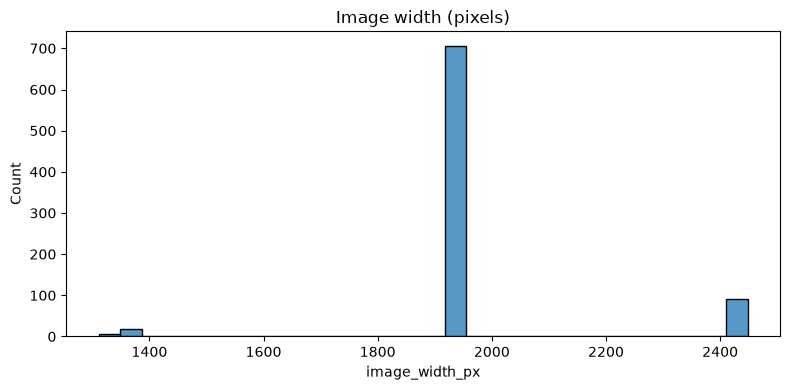

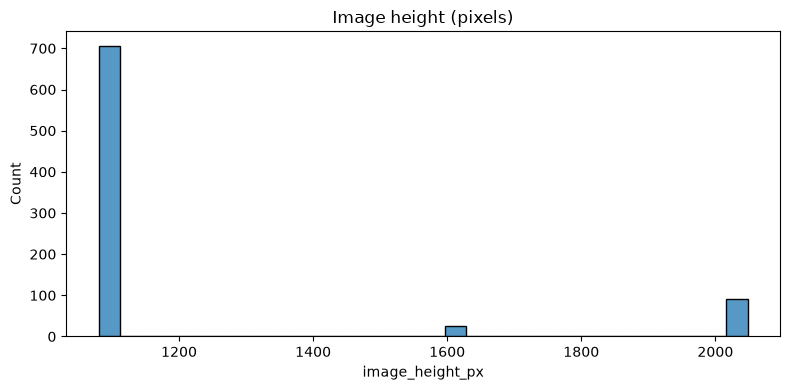

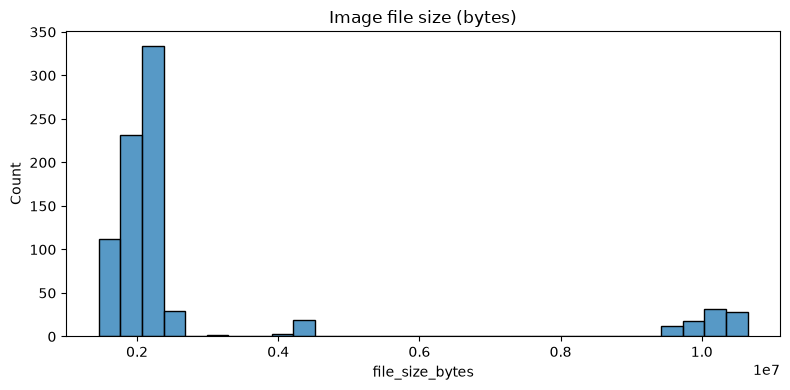

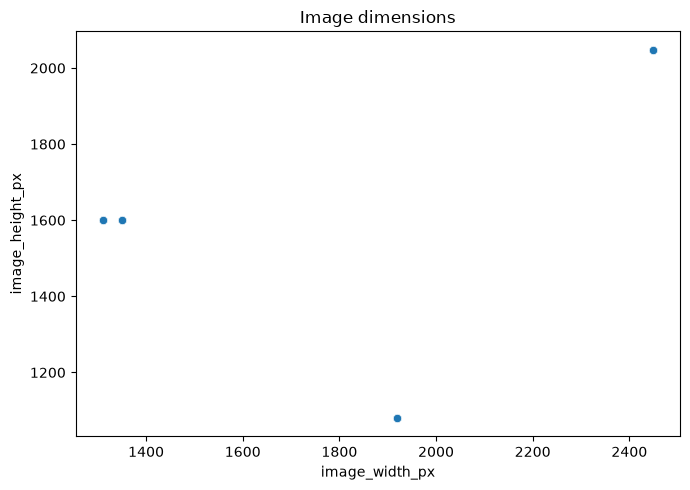

In [12]:
image_numeric_cols = [
    "image_width_px", "image_height_px", "total_pixels",
    "file_size_bytes", "channel_count", "total_annotations"
]
for col in image_numeric_cols:
    if col in images.columns:
        images[col] = pd.to_numeric(images[col], errors="coerce")

if {"image_width_px", "image_height_px"}.issubset(images.columns):
    images["aspect_ratio_eda"] = images["image_width_px"] / images["image_height_px"]
    display(images[["image_width_px", "image_height_px", "aspect_ratio_eda"]].describe().T)
else:
    print("Width/height fields are unavailable; image aspect ratio cannot be calculated.")

for col in ["image_format", "image_mode", "channel_count"]:
    if col in images.columns:
        print(f"\n{col} distribution")
        display(images[col].value_counts(dropna=False).rename_axis(col).to_frame("count"))

available_props = [c for c in image_numeric_cols if c in images.columns]
display(images[available_props].describe().T)
images[available_props].describe().T.to_csv(TABLES_DIR / "image_numeric_summary.csv")

for col, filename, title in [
    ("image_width_px", "image_width_distribution.png", "Image width (pixels)"),
    ("image_height_px", "image_height_distribution.png", "Image height (pixels)"),
    ("file_size_bytes", "image_file_size_distribution.png", "Image file size (bytes)"),
    ("total_annotations", "annotations_per_image_distribution.png", "Annotations per image"),
]:
    if col in images.columns:
        series = pd.to_numeric(images[col], errors="coerce").dropna()
        if len(series):
            fig, ax = plt.subplots(figsize=(8, 4))
            sns.histplot(series, bins=30, ax=ax)
            ax.set_title(title)
            ax.set_xlabel(col)
            fig.tight_layout()
            fig.savefig(PLOTS_DIR / filename, dpi=160, bbox_inches="tight")
            plt.show()

if {"image_width_px", "image_height_px"}.issubset(images.columns):
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.scatterplot(data=images, x="image_width_px", y="image_height_px", ax=ax)
    ax.set_title("Image dimensions")
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / "image_dimensions_scatter.png", dpi=160, bbox_inches="tight")
    plt.show()


In [13]:
required_geom = [
    "image_id", "x1_px", "y1_px", "x2_px", "y2_px",
    "bbox_width_px", "bbox_height_px", "bbox_area_px2"
]
missing_geom = [c for c in required_geom if c not in annotations.columns]
if missing_geom:
    print("Cannot run full geometry validation; missing columns:", missing_geom)
else:
    geom = annotations.copy()
    for col in required_geom[1:]:
        geom[col] = pd.to_numeric(geom[col], errors="coerce")

    geom["calc_width_px"] = geom["x2_px"] - geom["x1_px"]
    geom["calc_height_px"] = geom["y2_px"] - geom["y1_px"]
    geom["calc_area_px2"] = geom["calc_width_px"] * geom["calc_height_px"]

    # Join image dimensions for an independent boundary check.
    image_dims = images[["image_id", "image_width_px", "image_height_px"]].drop_duplicates("image_id")
    geom = geom.merge(image_dims, on="image_id", how="left", suffixes=("", "_image"))

    geom["negative_width_from_coords"] = geom["calc_width_px"] < 0
    geom["negative_height_from_coords"] = geom["calc_height_px"] < 0
    geom["zero_width_from_coords"] = geom["calc_width_px"] == 0
    geom["zero_height_from_coords"] = geom["calc_height_px"] == 0
    geom["stored_width_mismatch"] = ~np.isclose(
        geom["bbox_width_px"], geom["calc_width_px"], equal_nan=False, rtol=1e-5, atol=1e-5
    )
    geom["stored_height_mismatch"] = ~np.isclose(
        geom["bbox_height_px"], geom["calc_height_px"], equal_nan=False, rtol=1e-5, atol=1e-5
    )
    geom["stored_area_mismatch"] = ~np.isclose(
        geom["bbox_area_px2"], geom["calc_area_px2"], equal_nan=False, rtol=1e-5, atol=1e-5
    )

    dims_available = geom["image_width_px"].notna() & geom["image_height_px"].notna()
    geom["calc_out_of_bounds"] = np.where(
        dims_available,
        (geom["x1_px"] < 0) | (geom["y1_px"] < 0)
        | (geom["x2_px"] > geom["image_width_px"])
        | (geom["y2_px"] > geom["image_height_px"]),
        np.nan,
    )

    geom_issue_cols = [
        "negative_width_from_coords", "negative_height_from_coords",
        "zero_width_from_coords", "zero_height_from_coords",
        "stored_width_mismatch", "stored_height_mismatch",
        "stored_area_mismatch"
    ]
    geom_summary = pd.DataFrame({
        "check": geom_issue_cols,
        "records_flagged": [int(geom[c].fillna(False).sum()) for c in geom_issue_cols]
    })
    display(geom_summary)
    geom_summary.to_csv(TABLES_DIR / "geometry_validation_summary.csv", index=False)

    suspicious_mask = geom[geom_issue_cols].fillna(False).any(axis=1)
    suspicious_geom = geom.loc[suspicious_mask].copy()
    suspicious_geom.to_csv(TABLES_DIR / "geometry_records_for_review.csv", index=False)

    # Compare the stored flag to independent calculation where dimensions exist.
    if "is_out_of_bounds" in geom.columns:
        stored_flag = geom["is_out_of_bounds"].astype(str).str.lower().map(
            {"true": True, "false": False, "1": True, "0": False}
        )
        compare_mask = dims_available & stored_flag.notna() & geom["calc_out_of_bounds"].notna()
        disagreements = geom.loc[
            compare_mask & (stored_flag != geom["calc_out_of_bounds"].astype(bool))
        ]
        print("Stored vs recalculated out-of-bounds disagreements:", len(disagreements))
        disagreements.to_csv(TABLES_DIR / "out_of_bounds_flag_disagreements.csv", index=False)

    display(suspicious_geom.head(20))


,check,records_flagged
0,negative_width_from_coords,0
1,negative_height_from_coords,0
2,zero_width_from_coords,0
3,zero_height_from_coords,0
4,stored_width_mismatch,0
5,stored_height_mismatch,0
6,stored_area_mismatch,0


,image_id,annotation_id,label,shape_type,points_json,annotation_flags,x1_px,y1_px,x2_px,y2_px,...,image_width_px,image_height_px,negative_width_from_coords,negative_height_from_coords,zero_width_from_coords,zero_height_from_coords,stored_width_mismatch,stored_height_mismatch,stored_area_mismatch,calc_out_of_bounds


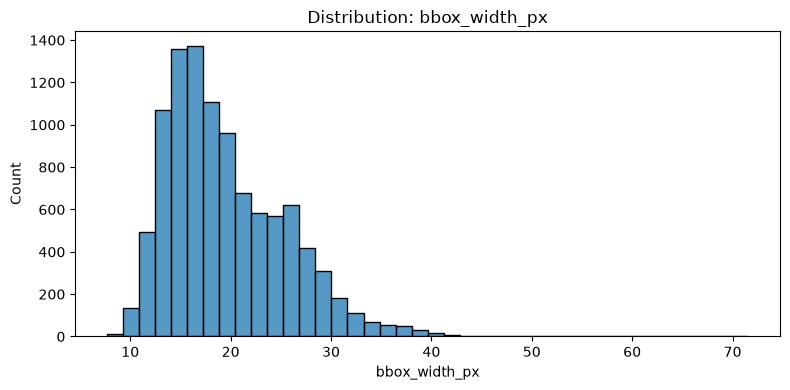

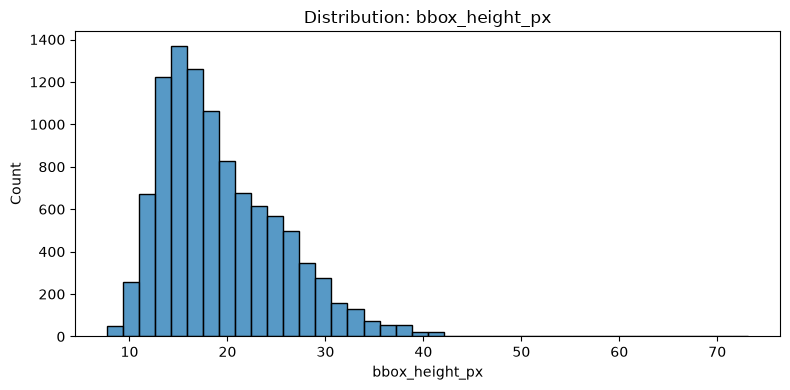

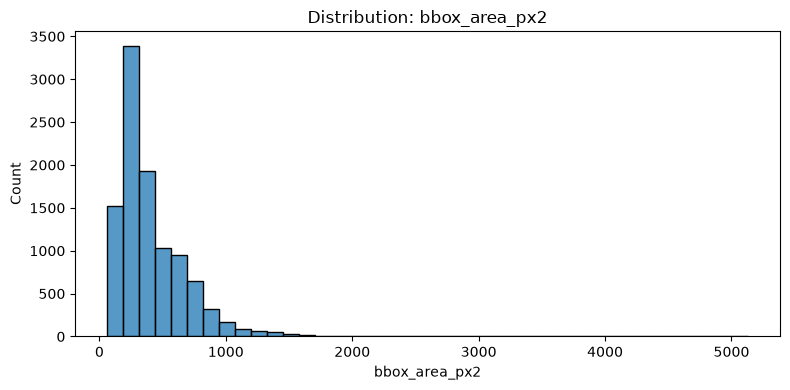

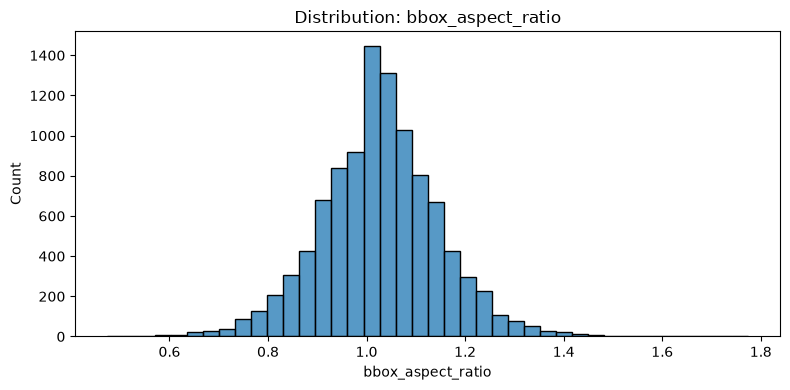

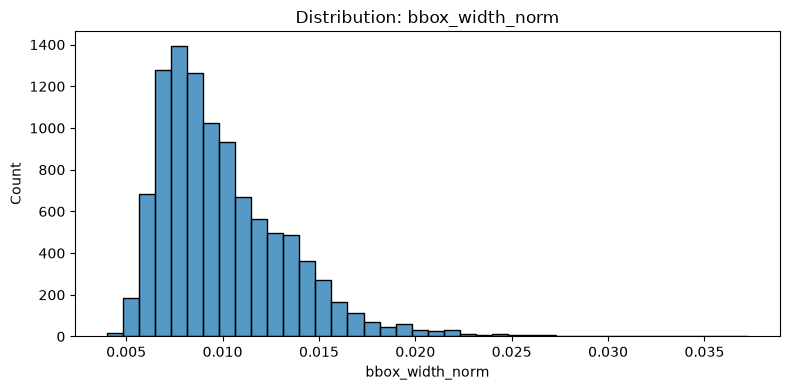

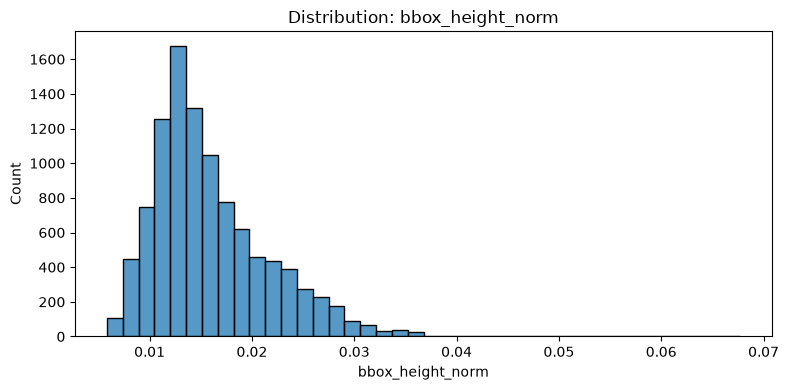

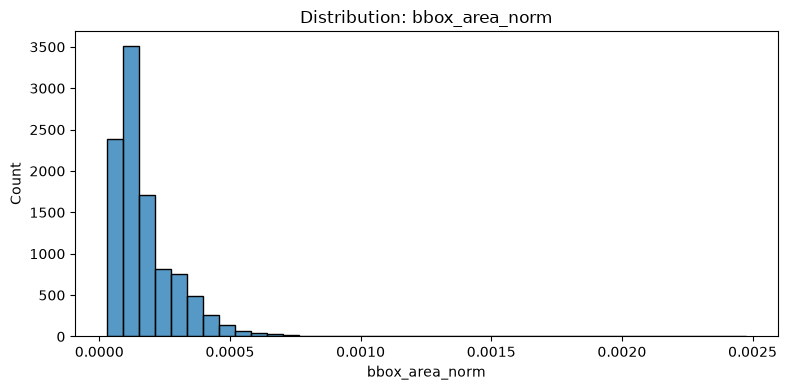

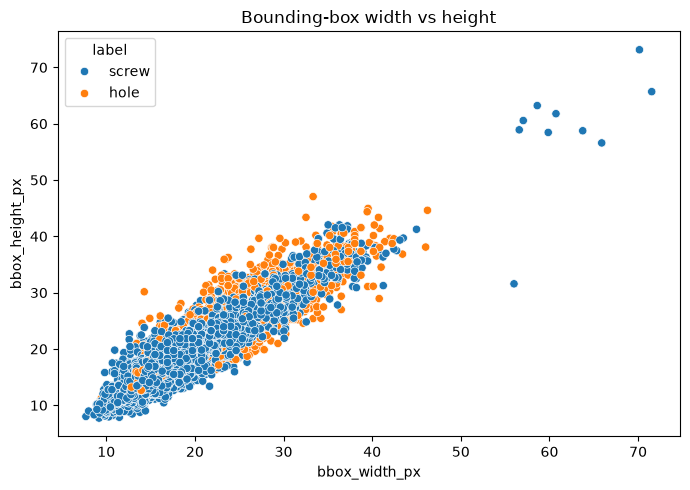

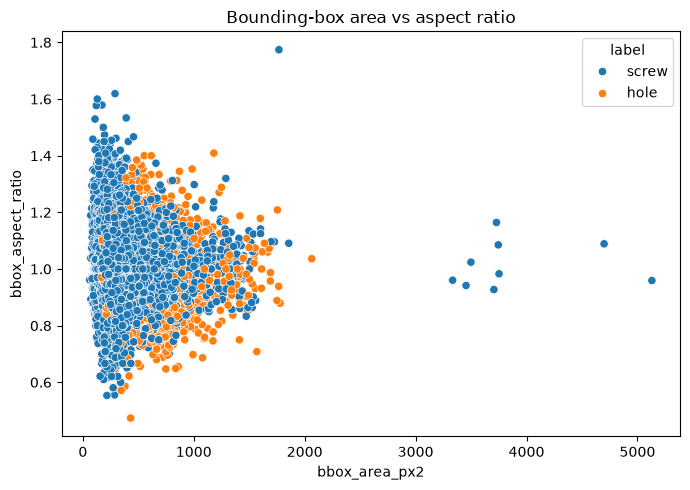

,annotation_id,image_id,label,feature,value,iqr_lower_bound,iqr_upper_bound,review_reason
0,00002_rectangle_000001,290ddaf57099e6e6,hole,bbox_width_px,39.495798,2.715713,35.809947,bbox_width_px outside 1.5*IQR range
1,00036_rectangle_000008,d8435b4a82e4b9ce,hole,bbox_width_px,36.507937,2.715713,35.809947,bbox_width_px outside 1.5*IQR range
2,00065_rectangle_000005,474b35f4053811aa,hole,bbox_width_px,36.507937,2.715713,35.809947,bbox_width_px outside 1.5*IQR range
3,00106_rectangle_000024,c9ac0dee389e4714,hole,bbox_width_px,37.391304,2.715713,35.809947,bbox_width_px outside 1.5*IQR range
4,00111_rectangle_000001,ef6db2ee8c36bfe8,screw,bbox_width_px,65.891473,2.715713,35.809947,bbox_width_px outside 1.5*IQR range
5,00115_rectangle_000001,b527cdef3923135e,screw,bbox_width_px,59.859155,2.715713,35.809947,bbox_width_px outside 1.5*IQR range
6,00137_rectangle_000006,0140b9e87c370639,hole,bbox_width_px,40.000000,2.715713,35.809947,bbox_width_px outside 1.5*IQR range
7,00138_rectangle_000005,bb009dfef1225643,hole,bbox_width_px,42.011834,2.715713,35.809947,bbox_width_px outside 1.5*IQR range
8,00141_rectangle_000011,aa81943a6e3ba431,hole,bbox_width_px,36.507937,2.715713,35.809947,bbox_width_px outside 1.5*IQR range
9,00145_rectangle_000009,388150b049eae9db,hole,bbox_width_px,36.764706,2.715713,35.809947,bbox_width_px outside 1.5*IQR range


In [14]:
plot_features = [
    "bbox_width_px", "bbox_height_px", "bbox_area_px2",
    "bbox_aspect_ratio", "bbox_width_norm", "bbox_height_norm",
    "bbox_area_norm"
]
plot_features = [c for c in plot_features if c in annotations.columns]

for col in plot_features:
    values = pd.to_numeric(annotations[col], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
    if len(values):
        fig, ax = plt.subplots(figsize=(8, 4))
        sns.histplot(values, bins=40, ax=ax)
        ax.set_title(f"Distribution: {col}")
        fig.tight_layout()
        fig.savefig(PLOTS_DIR / f"{col}_histogram.png", dpi=160, bbox_inches="tight")
        plt.show()

if {"bbox_width_px", "bbox_height_px"}.issubset(annotations.columns):
    plot_df = annotations.copy()
    plot_df["bbox_width_px"] = pd.to_numeric(plot_df["bbox_width_px"], errors="coerce")
    plot_df["bbox_height_px"] = pd.to_numeric(plot_df["bbox_height_px"], errors="coerce")
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.scatterplot(data=plot_df, x="bbox_width_px", y="bbox_height_px", hue="label" if "label" in plot_df else None, ax=ax)
    ax.set_title("Bounding-box width vs height")
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / "bbox_width_vs_height.png", dpi=160, bbox_inches="tight")
    plt.show()

if {"bbox_area_px2", "bbox_aspect_ratio"}.issubset(annotations.columns):
    plot_df = annotations.copy()
    for c in ["bbox_area_px2", "bbox_aspect_ratio"]:
        plot_df[c] = pd.to_numeric(plot_df[c], errors="coerce")
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.scatterplot(data=plot_df, x="bbox_area_px2", y="bbox_aspect_ratio", hue="label" if "label" in plot_df else None, ax=ax)
    ax.set_title("Bounding-box area vs aspect ratio")
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / "bbox_area_vs_aspect_ratio.png", dpi=160, bbox_inches="tight")
    plt.show()

# IQR candidate outliers: transparent screening rule, not an error diagnosis.
outlier_rows = []
for col in plot_features:
    values = pd.to_numeric(annotations[col], errors="coerce")
    values = values.replace([np.inf, -np.inf], np.nan)
    valid = values.dropna()
    if len(valid) < 4:
        continue
    q1, q3 = valid.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    idx = values[(values < low) | (values > high)].index
    for row_idx in idx:
        row = annotations.loc[row_idx]
        outlier_rows.append({
            "annotation_id": row.get("annotation_id"),
            "image_id": row.get("image_id"),
            "label": row.get("label"),
            "feature": col,
            "value": values.loc[row_idx],
            "iqr_lower_bound": low,
            "iqr_upper_bound": high,
            "review_reason": f"{col} outside 1.5*IQR range",
        })

outliers_df = pd.DataFrame(outlier_rows)
display(outliers_df.head(30))
outliers_df.to_csv(TABLES_DIR / "iqr_outlier_candidates.csv", index=False)


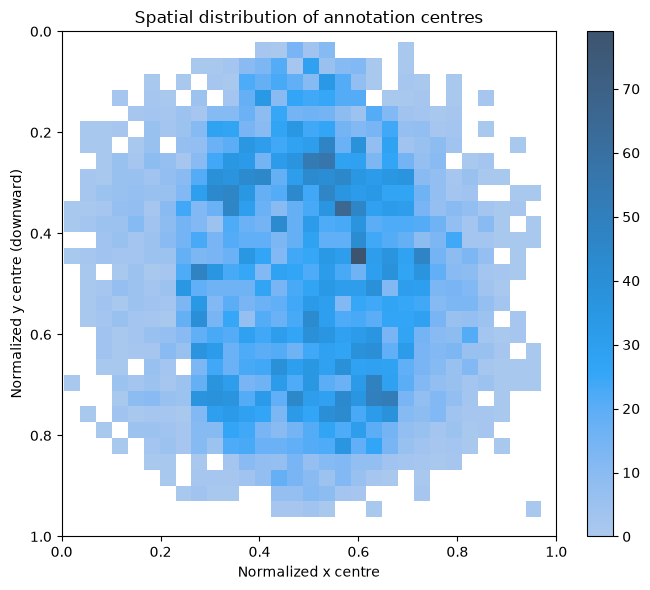

Centres included in plot: 10226 of 10226


In [15]:
centre_cols = ["bbox_x_center_norm", "bbox_y_center_norm"]
if all(c in annotations.columns for c in centre_cols):
    spatial = annotations[centre_cols].apply(pd.to_numeric, errors="coerce")
    spatial = spatial.replace([np.inf, -np.inf], np.nan).dropna()
    spatial = spatial[
        spatial["bbox_x_center_norm"].between(0, 1)
        & spatial["bbox_y_center_norm"].between(0, 1)
    ]

    fig, ax = plt.subplots(figsize=(7, 6))
    if len(spatial):
        sns.histplot(
            data=spatial,
            x="bbox_x_center_norm",
            y="bbox_y_center_norm",
            bins=30,
            cbar=True,
            ax=ax
        )
    ax.set_xlim(0, 1)
    ax.set_ylim(1, 0)
    ax.set_xlabel("Normalized x centre")
    ax.set_ylabel("Normalized y centre (downward)")
    ax.set_title("Spatial distribution of annotation centres")
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / "annotation_centre_heatmap.png", dpi=160, bbox_inches="tight")
    plt.show()
    print("Centres included in plot:", len(spatial), "of", len(annotations))
else:
    print("Normalized centre columns not available; spatial analysis skipped.")


Candidate features: ['bbox_width_px', 'bbox_height_px', 'bbox_area_px2', 'bbox_aspect_ratio', 'bbox_width_norm', 'bbox_height_norm', 'bbox_area_norm', 'bbox_x_center_norm', 'bbox_y_center_norm']
Features retained after missing/constant checks: ['bbox_width_px', 'bbox_height_px', 'bbox_area_px2', 'bbox_aspect_ratio', 'bbox_width_norm', 'bbox_height_norm', 'bbox_area_norm', 'bbox_x_center_norm', 'bbox_y_center_norm']
Rows with at least one usable measurement: 10226
Pairwise valid observation counts:


,bbox_width_px,bbox_height_px,bbox_area_px2,bbox_aspect_ratio,bbox_width_norm,bbox_height_norm,bbox_area_norm,bbox_x_center_norm,bbox_y_center_norm
bbox_width_px,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0
bbox_height_px,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0
bbox_area_px2,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0
bbox_aspect_ratio,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0
bbox_width_norm,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0
bbox_height_norm,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0
bbox_area_norm,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0
bbox_x_center_norm,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0
bbox_y_center_norm,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0,10226.0


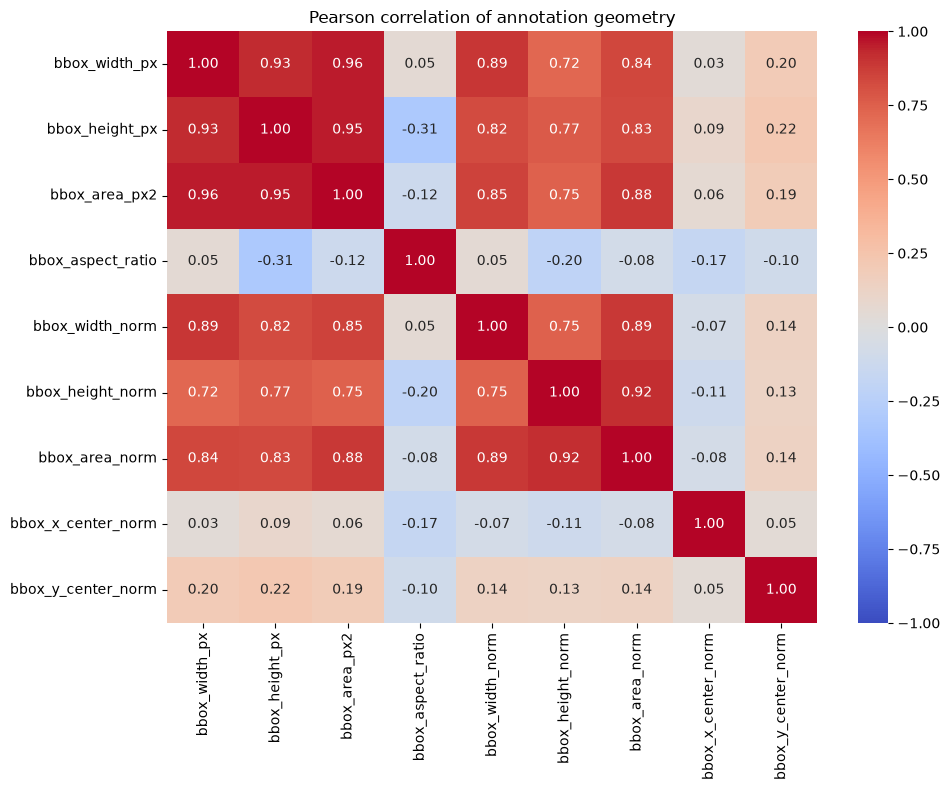

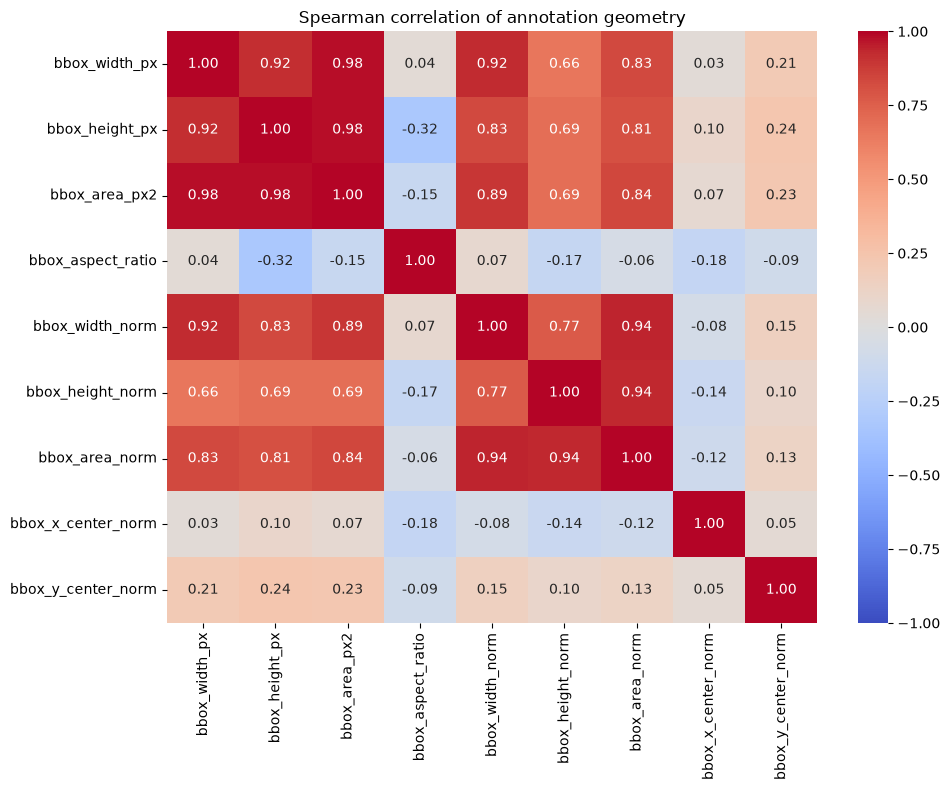

In [16]:
correlation_candidates = [
    "bbox_width_px", "bbox_height_px", "bbox_area_px2",
    "bbox_aspect_ratio", "bbox_width_norm", "bbox_height_norm",
    "bbox_area_norm", "bbox_x_center_norm", "bbox_y_center_norm"
]
correlation_candidates = [c for c in correlation_candidates if c in annotations.columns]

corr_data = annotations[correlation_candidates].copy()
for col in correlation_candidates:
    corr_data[col] = pd.to_numeric(corr_data[col], errors="coerce")
corr_data = corr_data.replace([np.inf, -np.inf], np.nan)

# Exclude constant or all-missing features.
usable_cols = [
    c for c in corr_data.columns
    if corr_data[c].notna().sum() >= 2 and corr_data[c].nunique(dropna=True) > 1
]
corr_data = corr_data[usable_cols]

print("Candidate features:", correlation_candidates)
print("Features retained after missing/constant checks:", usable_cols)
print("Rows with at least one usable measurement:", int(corr_data.notna().any(axis=1).sum()))
print("Pairwise valid observation counts:")
display(corr_data.corr(method="pearson", min_periods=2) * 0 + corr_data.notna().astype(int).T.dot(corr_data.notna().astype(int)))

if len(usable_cols) >= 2:
    pearson = corr_data.corr(method="pearson", min_periods=2)
    spearman = corr_data.corr(method="spearman", min_periods=2)
    pearson.to_csv(TABLES_DIR / "pearson_correlation.csv")
    spearman.to_csv(TABLES_DIR / "spearman_correlation.csv")

    for matrix, name in [(pearson, "pearson"), (spearman, "spearman")]:
        fig, ax = plt.subplots(figsize=(10, 8))
        sns.heatmap(matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
        ax.set_title(f"{name.title()} correlation of annotation geometry")
        fig.tight_layout()
        fig.savefig(PLOTS_DIR / f"{name}_correlation_heatmap.png", dpi=160, bbox_inches="tight")
        plt.show()
else:
    print("Not enough varying numeric features for correlation matrices.")


In [17]:
from PIL import Image, ImageDraw
import random

DATASET_DIR = Path(config.DATASET_DIR)
if not DATASET_DIR.is_absolute():
    DATASET_DIR = (PROJECT_ROOT / DATASET_DIR).resolve()

SAMPLE_SEED = 42
SAMPLE_SIZE = 8

if not DATASET_DIR.is_dir():
    print("Dataset directory is not available at configured path:", DATASET_DIR)
else:
    image_file_column = "image_filename" if "image_filename" in images.columns else None
    if image_file_column is None:
        print("No image_filename field in image metadata; cannot resolve source images.")
    else:
        candidates = images.dropna(subset=["image_id", image_file_column]).copy()
        candidates = candidates[candidates[image_file_column].map(lambda x: (DATASET_DIR / str(x)).is_file())]
        sample = candidates.sample(n=min(SAMPLE_SIZE, len(candidates)), random_state=SAMPLE_SEED)

        for _, image_row in sample.iterrows():
            image_path = DATASET_DIR / str(image_row[image_file_column])
            try:
                with Image.open(image_path) as im:
                    canvas = im.convert("RGB")
                draw = ImageDraw.Draw(canvas)

                image_anns = annotations[annotations["image_id"].astype(str) == str(image_row["image_id"])]
                for _, ann in image_anns.iterrows():
                    coords = [ann.get(c) for c in ["x1_px", "y1_px", "x2_px", "y2_px"]]
                    if any(pd.isna(v) for v in coords):
                        continue
                    x1, y1, x2, y2 = map(float, coords)
                    draw.rectangle((x1, y1, x2, y2), outline="red", width=2)
                    label_text = f"{ann.get('label', '')} | {ann.get('annotation_id', '')}"
                    draw.text((x1, max(0, y1 - 12)), label_text, fill="yellow", stroke_width=1, stroke_fill="black")

                output_path = SAMPLES_DIR / f"overlay_{image_row['image_id']}.png"
                canvas.save(output_path)
                print(f"Image ID: {image_row['image_id']} | annotations: {len(image_anns)} | saved: {output_path}")
                display(canvas)
            except Exception as exc:
                print(f"Could not visualize {image_path.name}: {exc}")


No image_filename field in image metadata; cannot resolve source images.


In [18]:
if "image_checksum_sha256" in images.columns:
    checksum_df = images[images["image_checksum_sha256"].notna()].copy()
    duplicate_checksum_mask = checksum_df["image_checksum_sha256"].duplicated(keep=False)
    duplicate_content = checksum_df.loc[duplicate_checksum_mask].sort_values("image_checksum_sha256")
    print("Rows with a duplicated SHA-256 checksum:", len(duplicate_content))
    display(duplicate_content[[
        c for c in ["image_id", "image_filename", "image_checksum_sha256"]
        if c in duplicate_content.columns
    ]].head(50))
    duplicate_content.to_csv(TABLES_DIR / "duplicate_image_checksums.csv", index=False)
else:
    print("No SHA-256 checksum field; duplicate-content analysis not available.")

if "dataset_split" in images.columns:
    print("Image split values:")
    display(images["dataset_split"].value_counts(dropna=False).rename_axis("dataset_split").to_frame("count"))
else:
    print("No dataset_split column; split assignment is not recorded.")


No SHA-256 checksum field; duplicate-content analysis not available.
No dataset_split column; split assignment is not recorded.


In [19]:
readiness_rows = []

def add_check(check, status, evidence, rule):
    readiness_rows.append({
        "check": check,
        "status": status,
        "evidence": evidence,
        "rule_or_limitation": rule,
    })

# Required input files
add_check(
    "Required CSV files",
    "PASS" if all(p.is_file() for p in input_paths.values()) else "FAIL",
    f"{sum(p.is_file() for p in input_paths.values())}/4 files exist",
    "PASS only when all four configured CSV inputs exist."
)

# Schema completeness
schema_missing_count = len(schema_issues_df)
add_check(
    "Required columns",
    "PASS" if schema_missing_count == 0 else "FAIL",
    f"{schema_missing_count} missing required column(s)",
    "PASS when required image and annotation fields are present."
)

# Extraction errors are a warning if any are present.
error_count = len(image_errors) + len(annotation_errors)
add_check(
    "Extraction errors",
    "PASS" if error_count == 0 else "WARNING",
    f"{len(image_errors)} image errors; {len(annotation_errors)} annotation errors",
    "WARNING if any extraction errors exist; inspect error CSVs before deciding whether records can be recovered."
)

# Duplicate IDs
duplicate_id_rows = (
    duplicate_count(images["image_id"]) if "image_id" in images else 0
) + (
    duplicate_count(annotations["annotation_id"]) if "annotation_id" in annotations else 0
)
add_check(
    "Identifier uniqueness",
    "PASS" if duplicate_id_rows == 0 else "FAIL",
    f"{duplicate_id_rows} rows belong to duplicate ID groups",
    "PASS when image_id and annotation_id are unique within their respective tables."
)

# Unknown annotation references
unknown_ref_count = len(annotation_image_ids - image_id_set)
add_check(
    "Annotation-to-image references",
    "PASS" if unknown_ref_count == 0 else "FAIL",
    f"{unknown_ref_count} annotation image ID(s) absent from image metadata",
    "PASS when every annotation image_id matches an image metadata record."
)

# Split status
split_exists = "dataset_split" in images.columns and images["dataset_split"].notna().any()
add_check(
    "Train/validation/test split",
    "PASS" if split_exists else "NOT ASSESSED",
    "At least one split value exists" if split_exists else "No populated split assignment found",
    "A split must be deliberately created, preferably grouped by source/image identity to avoid leakage."
)

# Visual review remains a human decision.
add_check(
    "Visual annotation verification",
    "NOT ASSESSED",
    "Overlay review must be completed by inspecting saved sample visualizations",
    "Human review is required to confirm box alignment, label correctness, and missed objects."
)

readiness = pd.DataFrame(readiness_rows)
display(readiness)
readiness.to_csv(TABLES_DIR / "training_readiness_checklist.csv", index=False)


,check,status,evidence,rule_or_limitation
0,Required CSV files,PASS,4/4 files exist,PASS only when all four configured CSV inputs ...
1,Required columns,FAIL,6 missing required column(s),PASS when required image and annotation fields...
2,Extraction errors,PASS,0 image errors; 0 annotation errors,WARNING if any extraction errors exist; inspec...
3,Identifier uniqueness,PASS,0 rows belong to duplicate ID groups,PASS when image_id and annotation_id are uniqu...
4,Annotation-to-image references,PASS,0 annotation image ID(s) absent from image met...,PASS when every annotation image_id matches an...
5,Train/validation/test split,NOT ASSESSED,No populated split assignment found,"A split must be deliberately created, preferab..."
6,Visual annotation verification,NOT ASSESSED,Overlay review must be completed by inspecting...,Human review is required to confirm box alignm...


In [20]:
report_lines = [
    "# VisionInspect AI — EDA Summary",
    "",
    f"- Analysis time (UTC): {datetime.now(timezone.utc).isoformat()}",
    f"- Project root: `{PROJECT_ROOT}`",
    f"- Dataset directory (configured): `{getattr(config, 'DATASET_DIR', 'not available')}`",
    "",
    "## Input files",
]
for name, path in input_paths.items():
    report_lines.append(f"- **{name}:** `{path}` — {'exists' if path.is_file() else 'MISSING'}")

report_lines += ["", "## Dataset sizes", ""]
for name, df in datasets.items():
    report_lines.append(f"- **{name}:** {len(df):,} rows × {df.shape[1]:,} columns")

report_lines += ["", "## Dataset summary", ""]
report_lines.append(dataset_summary.to_markdown(index=False))

report_lines += ["", "## Label distribution", ""]
report_lines.append(label_counts.to_markdown(index=False))

report_lines += ["", "## Readiness checklist", ""]
report_lines.append(readiness.to_markdown(index=False))

report_lines += [
    "",
    "## Limitations and next steps",
    "",
    "- Outliers are candidates for manual review, not automatic errors.",
    "- Correlations among derived geometry fields are descriptive and do not measure detector accuracy.",
    "- The extraction pipeline converts each LabelMe shape to its point-extrema bounding rectangle; this is not the same as polygon area.",
    "- Confirm the annotation policy for images with zero annotations.",
    "- Review extraction errors and rendered annotation overlays.",
    "- Establish leakage-resistant train/validation/test splits before training.",
    "- Evaluate the first detector on held-out images with agreed precision, recall, false-accept and false-reject criteria.",
]
report_path = EDA_DIR / "eda_report.md"
report_path.write_text("\n".join(report_lines), encoding="utf-8")
print("Report saved:", report_path)
print("Tables:", TABLES_DIR)
print("Plots:", PLOTS_DIR)
print("Visual samples:", SAMPLES_DIR)


Report saved: C:\Users\samya\PyCharmProject\industrial-vision-inspection\reports\eda\eda_report.md
Tables: C:\Users\samya\PyCharmProject\industrial-vision-inspection\reports\eda\tables
Plots: C:\Users\samya\PyCharmProject\industrial-vision-inspection\reports\eda\plots
Visual samples: C:\Users\samya\PyCharmProject\industrial-vision-inspection\reports\eda\samples
